## Abstract

A reusable, cloud-scalable pipeline that pairs Cellpose-SAM segmentation with on-demand GPU compute (Modal + S3) for single-cell phenotyping of high-content microscopy, demonstrated on a two-species yeast panel (*Saccharomyces cerevisiae* vs. *Schizosaccharomyces pombe*).

----

:::{.callout-note title="AI usage disclosure" collapse="true"}
This is a placeholder for the AI usage disclosure. Once all authors sign the AI code form on Airtable, SlackBot will message you an AI disclosure that you should place here.
:::

## Purpose

High-content microscopy makes it easy to generate far more images than any single workstation can segment in a reasonable time. The bottleneck usually isn't the science — it's the plumbing: moving images, standing up GPUs, and getting consistent per-cell measurements out the other side. This pub shows one clean way to remove that bottleneck by combining a strong general-purpose segmentation model with elastic cloud GPU compute, so segmentation scales with your dataset instead of your hardware.

**Key takeaways:**

1. Cellpose-SAM segmentation combined with cloud GPU compute is a reliable, flexible way to scale single-cell phenotyping across large microscopy datasets.
2. The phenotyping outputs resolve gross morphological differences between strains and conditions.

**Who this is for:** Researchers and computational biologists doing high-throughput microscopy who want a segmentation and phenotyping pipeline, or who are weighing how to scale segmentation compute without building bespoke infrastructure.

**What this is _not_:** No new biology, and not a Cellpose or Modal tutorial.

**What you can do with it:** Run the accompanying notebook end-to-end on the example data, or lift the pattern (file I/O → segmentation → scale-out → per-cell measurements) into your own setup.

## How the pipeline fits together

:::{.callout-note title="Draft figure" collapse="false"}
A designed hero figure (in progress with Audrey) will replace the schematic below. The Mermaid diagram is a functional stand-in that captures the intended flow.
:::

The workflow is a straight line from raw images to per-cell measurements, with one key property: the segmentation step is identical whether it runs on one machine or hundreds of GPU containers. Scale is a deployment choice, not a code rewrite.

```{mermaid}
flowchart LR
  A["Brightfield ND2s<br/>datasets/&lt;id&gt;/raw/"] --> B["File I/O + preprocessing<br/>arcadia-microscopy-tools"]
  B --> C["Segmentation<br/>Cellpose-SAM → label masks"]
  C --> D{"Scale-out<br/>one worker per image"}
  D --> E["Derived artifacts<br/>masks · overlays · measurements"]
  E --> F["Analysis<br/>pooled per-cell morphology"]
  P["Plate map<br/>well → strain"] --> F
```

1. **Input:** brightfield ND2s in object storage, organized as `datasets/<id>/raw/`, with a plate map linking wells to strains.
2. **File I/O and preprocessing:** `arcadia-microscopy-tools` handles ND2 reading, channel and pixel-size metadata, and percentile rescaling.
3. **Segmentation:** Cellpose-SAM produces label masks; border-touching cells are dropped.
4. **Scale-out:** one worker per image is fanned across on-demand GPU containers, each reading from and writing to shared cloud storage.
5. **Outputs (`derived/`):** label-mask TIFFs, outline-overlay JPGs for QC, and per-cell measurement CSVs (regionprops, in microns where the pixel size is known).
6. **Analysis:** pooled per-cell measurements joined to the plate map for morphology comparisons across strains.

## Example dataset

The demo runs on a two-species yeast panel: single-channel brightfield ND2s of two diploid strains with deliberately contrasting morphologies — the ovoid budding yeast *Saccharomyces cerevisiae* (BY4743) and the rod-shaped fission yeast *Schizosaccharomyces pombe* (SP286). The obvious shape difference makes this a clean illustration of differentiating cells by phenotype.

| Species | Strain | Wells | Morphology |
| --- | --- | --- | --- |
| *S. cerevisiae* | `BY4743` | K01–K04, L01–L04 | ovoid budding yeast |
| *S. pombe* | `SP286` | K05–K08, L05–L08 | rod-shaped fission yeast |

The full well-to-strain mapping lives in `plate-map.csv` alongside this notebook. The multiple wells per species are technical replicates, not independent biological replicates — a caveat we return to in the analysis and limitations.

**Acquisition (placeholder):** note the imaging modality, objective, and pixel size here, along with how wells map to ND2 filenames for this dataset.

**Where to get the data:** the example images are archived publicly so any reader can pull them (Zenodo record link to be added). Internal readers with bucket access read the same images directly from S3.

## Demo: single-cell segmentation at scale

The cells below run the full pipeline end to end: brightfield ND2s are segmented with Cellpose-SAM (via [`arcadia-microscopy-tools`](https://github.com/Arcadia-Science/arcadia-microscopy-tools)) into label masks, QC overlays, and per-cell measurement tables. The same segmentation code runs in one of two interchangeable modes, chosen automatically so the notebook is runnable whether or not you have our cloud infrastructure.

**Scaled mode (Modal + S3).** When the [Modal](https://modal.com/) client is authenticated and the `aws-s3-access-secret` (AWS credentials with read/write access to the `cloud-scaled-cell-phenotyping` bucket) is available, the heavy GPU compute is fanned out across Modal containers: each worker reads one ND2 from S3, segments it on a GPU, and writes the derived artifacts back to S3. The notebook only triggers the run and displays small previews returned by the workers. This is the path internal readers use, and it is what lets the pipeline keep pace with large datasets.

**Local mode (no cloud account required).** When that infrastructure is not available, the notebook falls back to running the identical Cellpose-SAM pipeline on your own machine (CPU by default). It downloads a few example ND2s from the public [Zenodo](https://zenodo.org/) archive over HTTPS, segments them locally, and writes the artifacts to a local folder. Because it runs on CPU, it is intentionally scoped to a few images via `limit`.

Either way, `run_demo` returns the same result object, so every downstream cell is unchanged across modes — underscoring that scaling is transparent to the analysis. As each image finishes, a progress bar ticks forward and shows that file's cell count. Set the environment variable `CSCP_FORCE_LOCAL=1` to force the local path, or pass `backend="modal"` / `backend="local"` explicitly.

In [ ]:
import time

from analysis.runner import run_demo

# The example dataset: single-channel brightfield ND2s under `datasets/<DATASET_ID>/raw/`.
DATASET_ID = "20260611_141152_330"

# The scaled Modal path segments the whole plate cheaply, so we process every well
# there; the local CPU fallback is capped to a few images to keep the demo fast.
# For the two-species comparison, make sure the local sample spans both cerevisiae
# (wells K01-K04/L01-L04) and pombe (K05-K08/L05-L08) wells; raise LIMIT if needed.
# LIMIT = None if modal_backend_available() else 3
LIMIT = 3

started = time.time()
run = run_demo(DATASET_ID, limit=LIMIT)
elapsed = time.time() - started

if run.backend == "modal":
    print(f"[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/{run.output_prefix}/")
else:
    print(f"[local] Wrote artifacts to {run.output_prefix}")
print(f"Segmented {len(run.results)} image(s), {len(run.failures)} failure(s) in {elapsed:.1f}s.")

Segmenting: 100%|██████████| 3/3 [01:47<00:00, 35.68s/img, 2713 cells · 8633 total]

[modal] Wrote artifacts to s3://cloud-scaled-cell-phenotyping/datasets/20260611_141152_330/derived/
Segmented 3 image(s), 0 failure(s) in 115.4s.


## Visual QC: segmentation overlays

The pipeline produces a small outline-overlay preview for each image (cell boundaries drawn on the brightfield image). We display a few here as a quick visual QC of the segmentation. Good segmentation traces each cell's boundary tightly without merging neighbors or splitting single cells; the pipeline drops cells touching the image border, since their measurements would be biased by truncation.

In [ ]:
from pathlib import Path

from IPython.display import Image as IPyImage
from IPython.display import display

for summary in run.results[:1]:
    overlay_path = summary.get("local_overlay")
    if overlay_path:
        print(f"{Path(summary['input']).name}: {summary['n_cells']} cells")
        display(IPyImage(filename=overlay_path, width=500))

## Per-cell phenotyping outputs

The pipeline also produces per-cell measurements (regionprops, converted to microns where the pixel size is known): one row per cell, with shape features such as area, eccentricity, and axis lengths. We pool them across the segmented images and join each cell to its species via the plate map (well → species), so every cell carries a species label for the analysis that follows.

The segmentation workers also write these tables to `derived/<dataset>/measurements/` in shared storage, so you don't have to re-segment to analyze them. By default we use the measurements from the run above, but setting `MEASUREMENTS_SOURCE` in the next cell to `"auto"` loads the full precomputed table for **every** well — from the S3 bucket (internal readers) or the public Zenodo archive (external readers). That's the easiest way to get both species in the analysis when the local demo only segmented a few images.

In [ ]:
import re
from pathlib import Path

import pandas as pd
from analysis.measurements import load_measurements

# Where the per-cell measurements come from:
#   "run"    - the table produced by the demo run above (only the images it
#              segmented; in local mode that is just LIMIT images from one species).
#   "auto"   - load the full precomputed table for the whole plate without
#              re-segmenting, from S3 (internal) or Zenodo (external). Use this to
#              analyze every well and both species.
#   "modal" / "zenodo" - force the S3 or Zenodo source explicitly.
MEASUREMENTS_SOURCE = "auto"

113379 cells across 2 species.


,image,label,area_um2,area_convex_um2,perimeter_um,eccentricity,solidity,axis_major_length_um,axis_minor_length_um,orientation,...,volume_um3,centroid_y,centroid_x,intensity_mean_brightfield,intensity_max_brightfield,intensity_min_brightfield,intensity_std_brightfield,well,species,strain
0,WellK01_PointK01_0000_Channelbrightfield_Seq0000,1,39.424531,40.665625,24.149153,0.706716,0.969481,8.435177,5.967868,0.523597,...,157.300913,25.133289,182.158741,6887.008038,12398.0,2088.0,2287.442962,K01,cerevisiae,BY4743
1,WellK01_PointK01_0000_Channelbrightfield_Seq0000,2,28.096250,28.941250,19.822198,0.629337,0.970803,6.794923,5.280557,0.509106,...,99.207091,19.604323,290.841165,7401.901316,12118.0,2275.0,2277.358963,K01,cerevisiae,BY4743
2,WellK01_PointK01_0000_Channelbrightfield_Seq0000,3,10.192813,10.747344,12.099075,0.374328,0.948403,3.773554,3.499203,1.236718,...,24.192865,10.569948,409.696891,6723.432642,11136.0,2209.0,1910.191530,K01,cerevisiae,BY4743
3,WellK01_PointK01_0000_Channelbrightfield_Seq0000,4,8.608438,9.110156,11.258694,0.675646,0.944928,3.882710,2.862435,-0.344135,...,16.657311,11.392638,1908.300614,6254.889571,9258.0,2624.0,1631.163261,K01,cerevisiae,BY4743
4,WellK01_PointK01_0000_Channelbrightfield_Seq0000,5,18.167500,18.774844,15.859672,0.611630,0.967651,5.417807,4.286265,-0.106277,...,52.117094,15.883721,1928.549419,6977.652616,13169.0,3022.0,2284.916041,K01,cerevisiae,BY4743


In [ ]:
if MEASUREMENTS_SOURCE == "run":
    measurements = run.measurements.copy()
else:
    measurements = load_measurements(DATASET_ID, source=MEASUREMENTS_SOURCE)


def _find_plate_map() -> Path:
    for candidate in (Path("plate-map.csv"), Path("../plate-map.csv")):
        if candidate.exists():
            return candidate
    raise FileNotFoundError("plate-map.csv not found next to the notebook or its parent.")


plate_map = pd.read_csv(_find_plate_map())


def well_from_name(name: str) -> str | None:
    """Pull a plate-well token (e.g. 'K01', 'WellL8') from an image name.

    DRAFT NOTE: confirm this matches the ND2 naming convention for your dataset.
    It normalizes to the plate-map form (uppercase row letter + zero-padded column).
    Rows span A-P so 384-well layouts (this dataset uses rows K/L) are covered.
    """
    match = re.search(r"(?:well[ _-]?)?([A-P])0*([1-9][0-9]?)", name, flags=re.IGNORECASE)
    if not match:
        return None
    return f"{match.group(1).upper()}{int(match.group(2)):02d}"


measurements["well"] = measurements["image"].map(well_from_name)
labeled = measurements.merge(plate_map[["well", "species", "strain"]], on="well", how="left")

n_unmapped = int(labeled["species"].isna().sum())
if n_unmapped:
    print(
        f"Warning: {n_unmapped} cell(s) had no species match; check well_from_name vs. your filenames."
    )
print(f"{len(labeled)} cells across {labeled['species'].nunique()} species.")
labeled.head()

## Minimal analysis and statistics

This section is intentionally minimal: the goal is to demonstrate the *kind* of phenotyping the pipeline enables, not to make a biological claim. We look at per-cell area distributions for the two species, a second shape feature (eccentricity), and a simple test of whether the two species' morphology distributions differ.

In [4]:
import matplotlib.pyplot as plt

try:
    import arcadia_pycolor as apc

    apc.mpl.setup()
except Exception:
    pass

GROUP_COL = "species"
REFERENCE = "cerevisiae"  # reference group the other species is compared against
area_col = "area_um2" if "area_um2" in labeled.columns else "area"
area_label = "cell area (µm²)" if area_col == "area_um2" else "cell area (px)"

analysis_df = labeled.dropna(subset=[GROUP_COL, area_col])
present = list(analysis_df[GROUP_COL].unique())
groups = ([REFERENCE] if REFERENCE in present else []) + sorted(
    g for g in present if g != REFERENCE
)

print(f"{len(analysis_df)} labeled cells across {len(groups)} species: {', '.join(groups)}")

113379 labeled cells across 2 species: cerevisiae, pombe


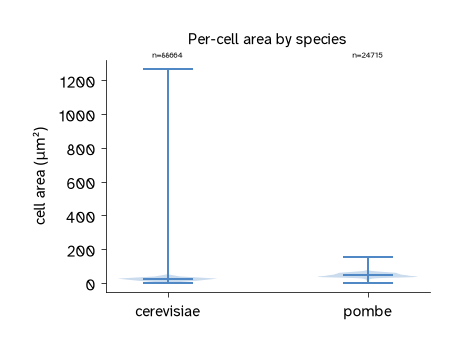

In [5]:
# Per-cell area distribution by species.
data = [analysis_df.loc[analysis_df[GROUP_COL] == g, area_col].to_numpy() for g in groups]

if len(groups) < 2:
    print(
        "Fewer than two species present. In local mode, raise LIMIT (or use the scaled path) "
        "so the sampled images span both cerevisiae and pombe wells."
    )
elif not data:
    print("No labeled cells to plot.")
else:
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.violinplot(data, showmedians=True)
    ax.set_xticks(range(1, len(groups) + 1))
    ax.set_xticklabels(groups, rotation=0, ha="center")
    ax.set_ylabel(area_label)
    ax.set_title("Per-cell area by species")
    y_top = ax.get_ylim()[1]
    for i, values in enumerate(data, start=1):
        ax.text(i, y_top, f"n={len(values)}", ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()

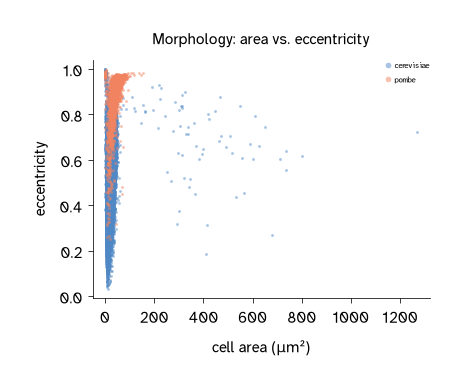

In [6]:
# A second shape feature: area vs. eccentricity, colored by species.
# Fission yeast (pombe) is elongated (higher eccentricity) than budding yeast (cerevisiae).
if analysis_df.empty:
    print("No labeled cells to plot.")
else:
    fig, ax = plt.subplots(figsize=(6, 5))
    for g in groups:
        sub = analysis_df[analysis_df[GROUP_COL] == g]
        ax.scatter(sub[area_col], sub["eccentricity"], s=8, alpha=0.5, label=g)
    ax.set_xlabel(area_label)
    ax.set_ylabel("eccentricity")
    ax.set_title("Morphology: area vs. eccentricity")
    ax.legend(markerscale=2, fontsize=8)
    plt.tight_layout()
    plt.show()

In [7]:
# Per-species summary: n cells, mean/median area, spread.
summary = (
    analysis_df.groupby(GROUP_COL)[area_col]
    .agg(n="count", mean="mean", median="median", std="std")
    .reindex(groups)
)
summary

,n,mean,median,std
species,,,,
cerevisiae,88664,23.754050,24.372969,14.595852
pombe,24715,46.226303,44.996250,11.688572


In [8]:
# Compare each species against the reference (cerevisiae) on a few shape features.
# Mann-Whitney U (two-sided), with a rank-biserial effect size for each feature.
from scipy.stats import mannwhitneyu

features = [(area_col, area_label), ("eccentricity", "eccentricity")]
ref_mask = analysis_df[GROUP_COL] == REFERENCE

rows = []
for other in (g for g in groups if g != REFERENCE):
    other_mask = analysis_df[GROUP_COL] == other
    for col, feat_label in features:
        ref_vals = analysis_df.loc[ref_mask, col].to_numpy()
        other_vals = analysis_df.loc[other_mask, col].to_numpy()
        if len(ref_vals) == 0 or len(other_vals) == 0:
            continue
        u_stat, p_val = mannwhitneyu(other_vals, ref_vals, alternative="two-sided")
        rank_biserial = 1.0 - (2.0 * u_stat) / (len(other_vals) * len(ref_vals))
        rows.append(
            {
                "species": other,
                "feature": feat_label,
                "n": len(other_vals),
                f"n_{REFERENCE}": len(ref_vals),
                "U": u_stat,
                "p": p_val,
                "rank_biserial": rank_biserial,
            }
        )

stats_df = pd.DataFrame(rows)
if stats_df.empty:
    print(
        f"Need both the reference ('{REFERENCE}') and another species present to run the comparison."
    )
stats_df

,species,feature,n,n_cerevisiae,U,p,rank_biserial
0,pombe,cell area (µm²),24715,88664,2.080917e+09,0.0,-0.899227
1,pombe,eccentricity,24715,88664,2.178827e+09,0.0,-0.988588


The pipeline cleanly resolves the two species by morphology: the rod-shaped fission yeast (*S. pombe*) separates from the ovoid budding yeast (*S. cerevisiae*) in both cell area and eccentricity, and the area-vs-eccentricity view pulls the elongated population apart from the rounder one. We draw no biological conclusions here — this single dataset, with technical-replicate wells per species, is enough to show that the pipeline produces usable, species-resolved phenotypes, not to make claims about the organisms.

## Limitations

- **Scope of the demo:** gross morphology only, from single-channel brightfield images. Staining- or fluorescence-based phenotyping is a natural extension, not shown here.
- **Compute and cost:** the scaled path relies on paid GPU compute and cloud storage. The local CPU fallback is deliberately scoped to a few images so anyone can reproduce the core result without an account, but it does not exercise the scale-out.
- **Replication:** a single dataset with multiple wells per species (technical, not biological, replicates) — enough to show the pipeline works, not to make claims about the organisms.

## Future directions

- Fluorescence and intensity phenotyping (e.g., BODIPY-stained yeast, or *Chlorella* chlorophyll autofluorescence).
- Larger panels and full-plate throughput, and additional organisms.

## Acknowledgements, references, and appendix

**Acknowledgements:** overview-figure design by Audrey; contributors and author list to be added.

**Tools and references:** [`arcadia-microscopy-tools`](https://github.com/Arcadia-Science/arcadia-microscopy-tools) (file I/O, preprocessing, measurements), Cellpose-SAM (segmentation), [Modal](https://modal.com/) (on-demand GPU compute), and Amazon S3 (shared storage). Full citations to be added.

**Run it yourself:** environment setup and step-by-step run instructions for both modes live in the repository README and project docs, kept out of the narrative so this pub reads as a blog post rather than a manual.

**Appendix (optional):** the segmentation knobs exposed by `SegmentConfig` — `diameter`, `flow_threshold`, `cellprob_threshold`, and the `percentile_low`/`percentile_high` contrast window — plus scaling parameters (`gpu`, `max_containers`) forwarded to the Modal workers.